# Introduction to Machine Learning

## Practice class 05 - Support Vector Machines

**Introduction**
Support Vector Machines (SVM) are a set of supervised learning methods used for classification, regression, and outlier detection. The main idea behind SVM is to find the optimal hyperplane that best separates the data points of different classes in a high-dimensional space. 

**Key Concepts:**
* **Hyperplane**: A hyperplane is a decision boundary that separates different classes in the feature space.
    * In 2D it is a line
    * In 3D it is a plane
    * In higher dimensions a hyperplane
* **Margin**: 
    * The margin is the distance between the hyperplane and the nearest data points from each class (support vectors).
    * The optimal hyperplane maximizes the margin between the support vectors of the two classes.
* **Support vector**: 
    * Support vectors are the data points that are closest to the hyperplane.
    * These points are critical in defining the position and orientation of the hyperplane.
* **Kernel Trick**:
    * SVM can efficiently perform a non-linear classification using the kernel trick.
    * The kernel trick involves transforming the data into a higher-dimensional space where a linear hyperplane can separate the classes.        
    * Common kernels include the linear kernel, polynomial kernel, radial basis function (RBF) kernel, and sigmoid kernel.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize

### Demo - Soft margin SVM
We will use a dataset containing two cloud of random points and calculate the equation of the line separating them.

In [2]:
N = 40
sigma = 0.6
np.random.seed(12345)
x = np.zeros((N,2),dtype=float)
x[:N//2,:] = np.array([np.random.normal(-1,sigma,size=N//2),np.random.normal(-1,sigma,size=N//2)]).T
x[N//2:,:] = np.array([np.random.normal(1,sigma,size=N//2),np.random.normal(1,sigma,size=N//2)]).T
t = np.zeros(N,dtype=int)
t[:N//2] = -1
t[N//2:] = 1

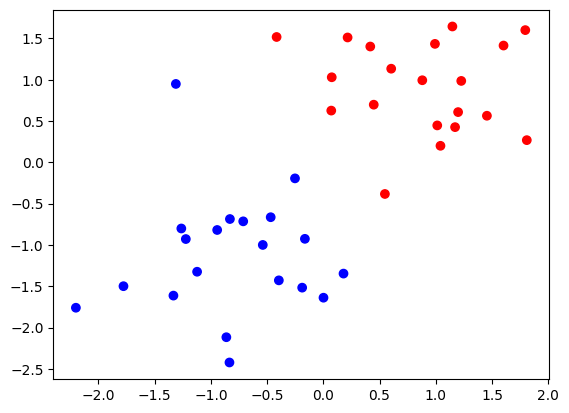

In [3]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')

### Hinge loss
We define the Hinge loss, which is the sum of the Hinge loss and a regularizator of the weight matrix

$$
L(t, f(\mathbf{x})) = \max(0, 1 - t \cdot f(\mathbf{x}))+ \dfrac{1}{2\lambda}\mathbf{w}^T \cdot \mathbf{w}\;, \quad \text{where} \quad f(\mathbf{x})=\mathbf{w}^T\cdot\mathbf{x}+b
$$

the first term used for the panelty of misclassification. The second term maximizes the margin.

In [4]:
def Hinge_loss(w,b,t,x,l):
    '''
    Compute the hinge loss
    :param w: weight vector
    :param b: bias
    :param t: target values
    :param x: input data
    :param l: regularization parameter
    :return: hinge loss
    '''
    return np.maximum(0,1-t*(np.dot(x,w)+b)).sum() + np.dot(w,w)/(2*l)

In [5]:
# Take random values for the weight vector and bias
w = np.random.normal(size=2)
b = np.random.normal()

In [6]:
Hinge_loss(w,b,t,x,0.1)

np.float64(92.248758020655)

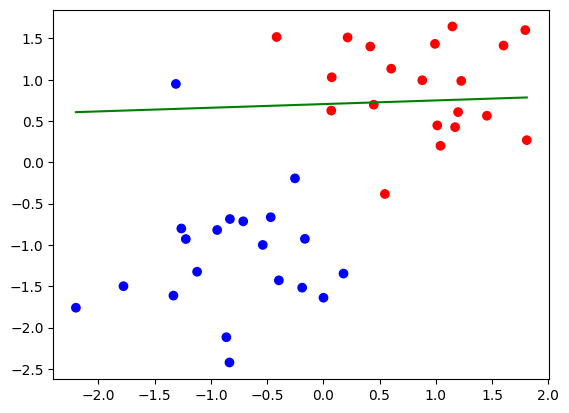

In [7]:
# plot the points and the random separating line
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')
xl = np.linspace(x[:,0].min(),x[:,0].max(),100)
plt.plot(xl,-(w[0]*xl+b)/w[1],"g-")

### Optimization
The random generated weight and bias is not a good separator, therefore the Hinge loss is very high.
We will do a very stupid random optimization in which we create new values for the weight and bias from the old one using normal distributed random numbers. We accept the new values if they decrease the value of the Hinge loss.

### First with soft margin: $\lambda = 0.1$

In [8]:
l = 0.1
for i in range(1000):
    wn = w + np.random.normal(size=2)
    bn = b + np.random.normal()
    if Hinge_loss(w,b,t,x,l) > Hinge_loss(wn,bn,t,x,l):
        w = wn.copy()
        b = bn


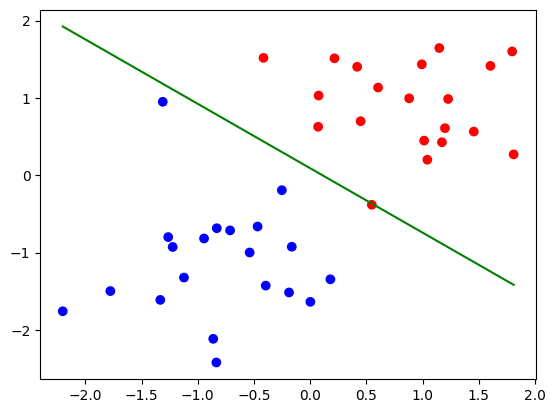

In [9]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')
xl = np.linspace(x[:,0].min(),x[:,0].max(),100)
plt.plot(xl,-(w[0]*xl+b)/w[1],"g-")

### Then with hard margin: $\lambda = 10^5$

In [10]:
l = 1e5
for i in range(10000):
    wn = w + np.random.normal(size=2)
    bn = b + np.random.normal()
    if Hinge_loss(w,b,t,x,l) > Hinge_loss(wn,bn,t,x,l):
        w = wn.copy()
        b = bn

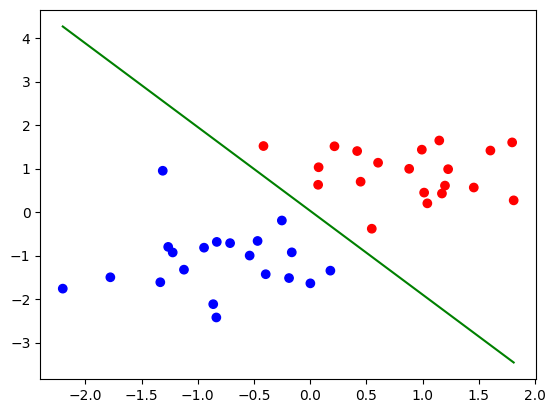

In [11]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')
xl = np.linspace(x[:,0].min(),x[:,0].max(),100)
plt.plot(xl,-(w[0]*xl+b)/w[1],"g-")

### Plot also the margins
Note that $|w|=1/C$

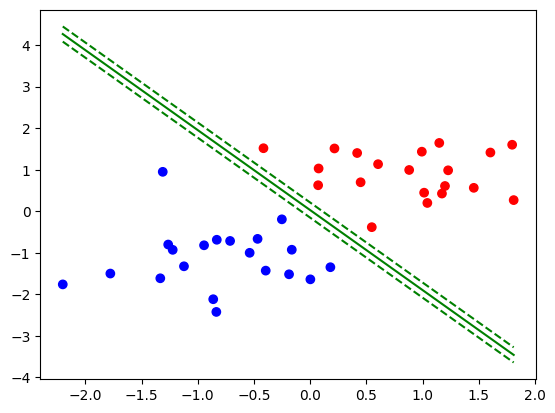

In [13]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')
xl = np.linspace(x[:,0].min(),x[:,0].max(),100)
plt.plot(xl,-(w[0]*xl+b)/w[1],"g-")
C = 1.0/np.linalg.norm(w)
plt.plot(xl,-(w[0]*xl+b+C)/w[1],"g--")
plt.plot(xl,-(w[0]*xl+b-C)/w[1],"g--")



# Demo – Soft Margin with Non-Separable Data (Linear Kernel)

### Idea

When data cannot be separated by a line, SVM introduces **slack variables** ( \xi_i ):

$$
\min_{w,b,\xi} \frac{1}{2}|w|^2 + C \sum_i \xi_i
$$

subject to

$$
t_i(w^Tx_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0
$$

* **large C** → penalize violations strongly → smaller margin, fewer violations
* **small C** → tolerate violations → larger margin


# Generate overlapping data

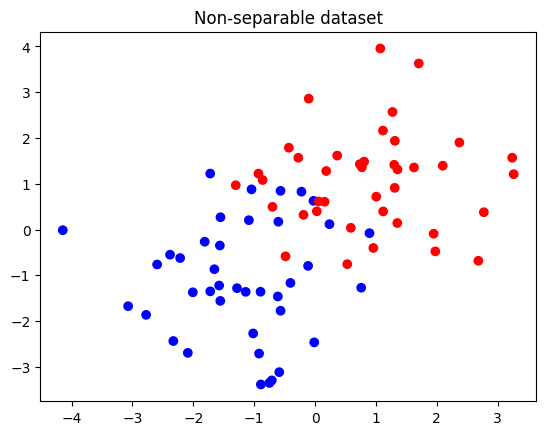

In [14]:
# Generate deliberately non-separable data
N = 80
sigma = 1.2
np.random.seed(42)

x = np.zeros((N,2))
x[:N//2] = np.random.normal([-1,-1], sigma, size=(N//2,2))
x[N//2:] = np.random.normal([1,1], sigma, size=(N//2,2))

t = np.zeros(N)
t[:N//2] = -1
t[N//2:] = 1

plt.scatter(x[:,0], x[:,1], c=t, cmap='bwr')
plt.title("Non-separable dataset")
plt.show()


## Train linear SVM with different C values

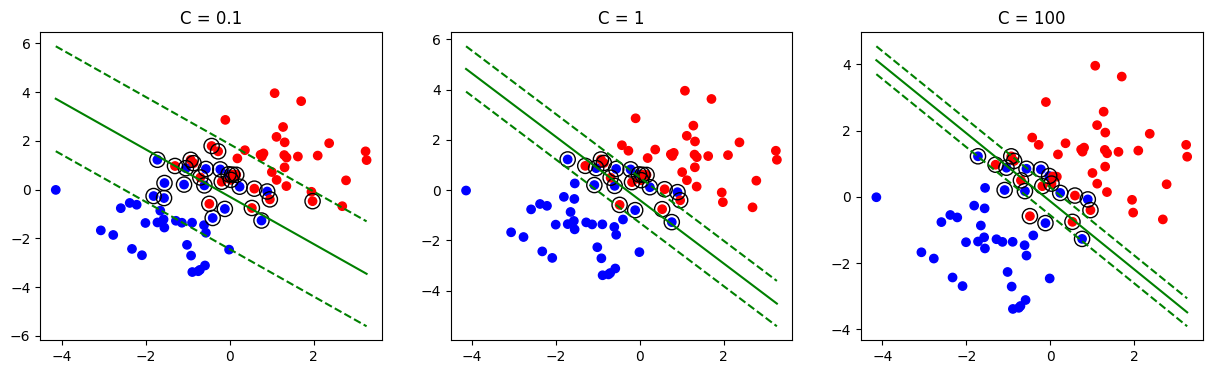

In [16]:
from sklearn.svm import SVC
C_values = [0.1, 1, 100]

plt.figure(figsize=(15,4))

for i,C in enumerate(C_values):

    model = SVC(kernel='linear', C=C)
    model.fit(x,t)

    w = model.coef_[0]
    b = model.intercept_[0]

    ax = plt.subplot(1,3,i+1)

    ax.scatter(x[:,0], x[:,1], c=t, cmap='bwr')

    # highlight support vectors
    ax.scatter(model.support_vectors_[:,0],
               model.support_vectors_[:,1],
               s=120,
               facecolors='none',
               edgecolors='k')

    xl = np.linspace(x[:,0].min(), x[:,0].max(),200)

    # decision boundary
    ax.plot(xl, -(w[0]*xl+b)/w[1], 'g')

    # margins
    margin = 1/np.linalg.norm(w)
    ax.plot(xl, -(w[0]*xl+b+margin)/w[1], 'g--')
    ax.plot(xl, -(w[0]*xl+b-margin)/w[1], 'g--')

    ax.set_title(f"C = {C}")

plt.show()


## Show margin violations

Points with

$$
t_i (w^Tx_i+b) < 1
$$

are **inside the margin or misclassified**.

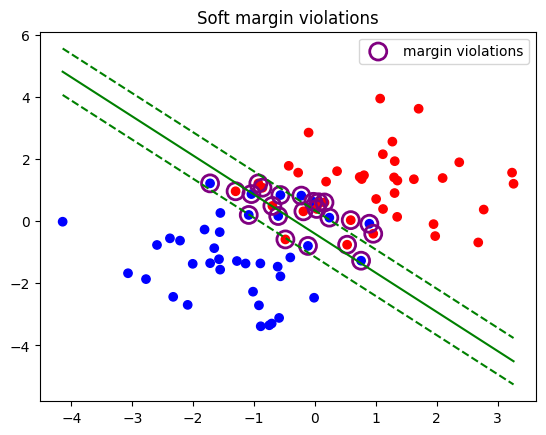

In [20]:
model = SVC(kernel='linear', C=1)
model.fit(x,t)

w = model.coef_[0]
b = model.intercept_[0]

decision = t*(x@w + b)

violations = decision < 1

plt.scatter(x[:,0], x[:,1], c=t, cmap='bwr')
plt.scatter(x[violations,0],
            x[violations,1],
            s=150,
            facecolors='none',
            edgecolors='purple',
            linewidths=2,
            label="margin violations")

xl = np.linspace(x[:,0].min(), x[:,0].max(),200)
plt.plot(xl, -(w[0]*xl+b)/w[1], 'g')

margin = 1/np.linalg.norm(w)
plt.plot(xl, -(w[0]*xl+b)/w[1] + margin, 'g--')
plt.plot(xl, -(w[0]*xl+b)/w[1] - margin, 'g--')

plt.legend()
plt.title("Soft margin violations")
plt.show()

### Demo - The kernel trick
There are cases when the data is not linearly separable. In this case we transform it to higher dimension dimension with a kernel where it is separable.

In [21]:
N = 100
sigma = 0.2
np.random.seed(12345)
x = np.zeros((N,2),dtype=float)
r = np.random.normal(1,sigma,size=N//2)
phi = np.random.random(N//2) * np.pi * 2.0
x[:N//2,:] = np.array([r * np.cos(phi),r * np.sin(phi)]).T
r = np.random.normal(0,sigma,size=N//2)
phi = np.random.random(N//2) * np.pi * 2.0
x[N//2:,:] = np.array([r * np.cos(phi),r * np.sin(phi)]).T
t = np.zeros(N,dtype=int)
t[:N//2] = -1
t[N//2:] = 1

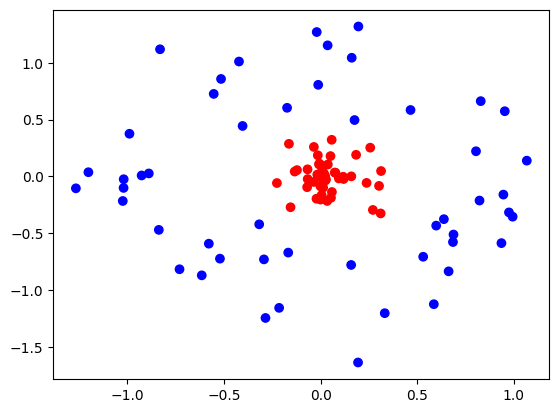

In [22]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')

In [23]:
w = np.random.normal(size=2)
b = np.random.normal()

In [24]:
l = 1e1
for i in range(10000):
    wn = w + np.random.normal(size=2)
    bn = b + np.random.normal()
    if Hinge_loss(w,b,t,x,l) > Hinge_loss(wn,bn,t,x,l):
        w = wn.copy()
        b = bn

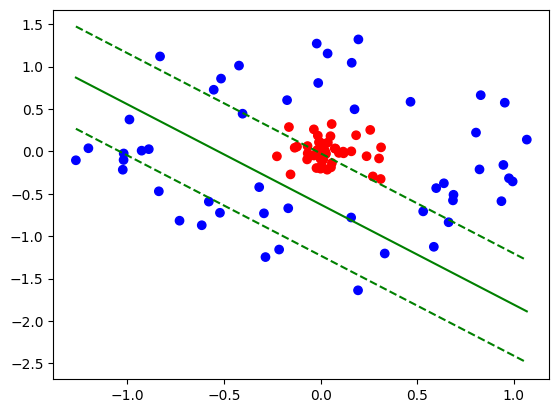

In [25]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')
xl = np.linspace(x[:,0].min(),x[:,0].max(),100)
plt.plot(xl,-(w[0]*xl+b)/w[1],"g-")
C = 1.0/np.linalg.norm(w)
plt.plot(xl,-(w[0]*xl+b)/w[1]-C,"g--")
plt.plot(xl,-(w[0]*xl+b)/w[1]+C,"g--")

In [26]:
x2 = np.array([x[:,0],x[:,1],x[:,0]**2,x[:,1]**2]).T

In [27]:
w2 = np.random.normal(size=4)
b2 = np.random.normal()

In [28]:
l = 1e5
for i in range(10000):
    wn = w2 + np.random.normal(size=4)
    bn = b2 + np.random.normal()
    
    if Hinge_loss(w2,b2,t,x2,l) > Hinge_loss(wn,bn,t,x2,l):
        w2 = wn.copy()
        b2 = bn

In [29]:
w2,b2,Hinge_loss(w2,b2,t,x2,l),((t*(np.dot(x2,w2)+b2))<0).sum()

(array([  1.6699458 ,  -0.53180313, -10.8063156 , -15.09663248]),
 2.9923217544795366,
 np.float64(0.0017387815141561896),
 np.int64(0))

In [30]:
xl = np.linspace(x2[:,0].min(),x2[:,0].max(),200)

In [31]:
# define a function to calculate 0 = w*x + b
def to_root(x2,pars):
    w,b,c,x1 = pars
    x1 = x1[0]
    x2 = x2[0]
    x = np.array([x1,x2,x1*x1,x2*x2])
    return np.dot(w,x) + b - c

In [32]:
# calculate the roots for the decision boundary and the margins
C = 1.0/np.linalg.norm(w)
root1 = [ optimize.root(to_root,-1,[w2,b2, 0,[x1]]).x[0] if optimize.root(to_root,-1,[w2,b2, 0,[x1]]).success else np.nan for x1 in xl ]
root2 = [ optimize.root(to_root, 1,[w2,b2, 0,[x1]]).x[0] if optimize.root(to_root, 1,[w2,b2, 0,[x1]]).success else np.nan for x1 in xl ]
b11 =   [ optimize.root(to_root,-1,[w2,b2, C,[x1]]).x[0] if optimize.root(to_root,-1,[w2,b2, C,[x1]]).success else np.nan for x1 in xl ]
b12 =   [ optimize.root(to_root, 1,[w2,b2, C,[x1]]).x[0] if optimize.root(to_root, 1,[w2,b2, C,[x1]]).success else np.nan for x1 in xl ]
b21 =   [ optimize.root(to_root,-1,[w2,b2,-C,[x1]]).x[0] if optimize.root(to_root,-1,[w2,b2,-C,[x1]]).success else np.nan for x1 in xl ]
b22 =   [ optimize.root(to_root, 1,[w2,b2,-C,[x1]]).x[0] if optimize.root(to_root, 1,[w2,b2,-C,[x1]]).success else np.nan for x1 in xl ]

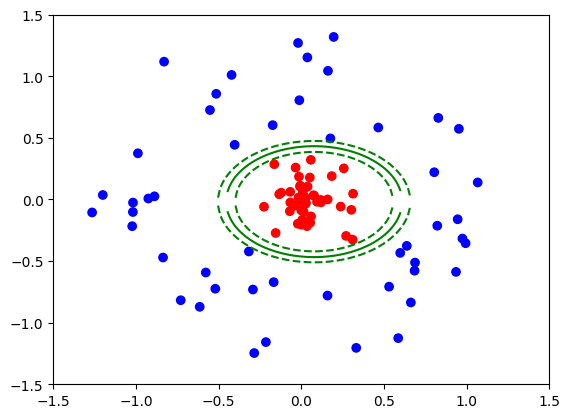

In [33]:
plt.scatter(x[:,0],x[:,1],c=t,cmap='bwr')
xl = np.linspace(x[:,0].min(),x[:,0].max(),200)
plt.xlim(-1.5,1.5)
plt.ylim(-1.5,1.5)
plt.plot(xl,root1,"g-")
plt.plot(xl,root2,"g-")
plt.plot(xl,b11,"g--")
plt.plot(xl,b12,"g--")
plt.plot(xl,b21,"g--")
plt.plot(xl,b22,"g--")
# plt.axis("equal")

### Task 1
Take the dataset from the soft SVM example (the two separated random clouds).
1. Solve the optimization problem for the previously defined Hinge loss with the built in minimizer of scipy `scipy.optimize.minimize`. Modify the implementation of the loss function if necessery. Plot the decision boundary and the margin. Compare the value of the loss function with the "stupid way of optimization".
2. Implement the built in SVC method of sklearn `sklearn.svm.SVC` to solve the classification program. Try to tune the parameters of the classifier to obtain the same result. 

### Task 2
Take the dataset from the kernel trick example (the two linearly not separable clouds).
1. Implement the built in SVC classifier with polinomial kernel and `degree=2`. Train the classifier.
2. Plot the original data and highlight the support vectors (calculated by the classifier).
3. Plot the decision boundary and the margin. For that create a meshgrid and use the `decision_function` method of the SVC classifier. Then create a contour plot with contour lines at [-1,0,1] representing the margins and the decision boundary.

### Task 3
Use the data below to perform a non-linear SVM classification. The dataset contains points along the $x$ axis. 
1. Introduce a second dimension as the square of the $x$ coordinate. Create a scattered plot of your 2 dimensional data.
2. Use the previously defined Hinge loss to calculate the weights and the bias.
3. Plot the decision boundary and the margin in the 2 dimensional space.
4. Also calculate the decision boundary by solving the $0=w_1 x + w_2 x^2 + b$ equation.

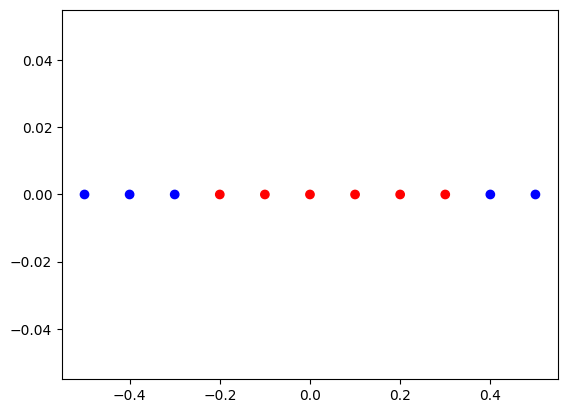

In [ ]:
x = np.array([-0.5,-0.4,-0.3,-0.2,-0.1,0.0,0.1,0.2,0.3,0.4,0.5])
t = np.array([-1,-1,-1,1,1,1,1,1,1,-1,-1])
plt.scatter(x,np.zeros_like(x),c=t,cmap='bwr')


### Homework - SVM Classification with the Breast Cancer Wisconsin Dataset
The goal of this exercise is to use Support Vector Machines (SVM) to classify data from the Breast Cancer Wisconsin dataset. 
1. Read the dataset from sklearn.datasets and perform a train test split. (1 point)
2. Create a pipeline from a `StandardScaler` and an `SVC` with linear kernel and fit the model. (1 point)
3. Plot the coefficients of the classifier as a horizontal bar plot, the features with larger weight are more important for the classification. What are the two most important features? (2 points)
4. To visualize the previous statement create a linear SVM classifier based on first the two most important and then the two less important features. Apply the two classifier to the test data and plot the decision boundaries. Calculate the accuracy of the two models. (3 points)
5. Show that if you know the most important features even a simple model is enought to predict up to high  
precision. Create a plot for different models including more and more features and show that the accuracy do not increase significantly with the added features. (2 points)
